In [ ]:
# import necessary packages
import platform
from pathlib import Path
import pandas as pd
import geopandas as gpd
import seaborn as sns
import calendar
import matplotlib.pyplot as plt
import pygris
from matplotlib.patches import Patch
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.patches import Rectangle

In [ ]:
# import fire data
# establish paths to datasets - fire
project_fldr = Path.cwd().parents[1]
raw_fldr = project_fldr / 'data' / 'raw'
processed_fldr = project_fldr / 'data' / 'processed'
figure_fldr = project_fldr/"figures"

# read in the processed fire dataset
fire_path = processed_fldr / "fire_shp_25" / "fire_shp_25.shp"
fire = gpd.read_file(fire_path)

In [3]:
# import wetland data
# establish paths to datasets - wetlands

# set a path to the main box folder based on machine's os
# if windows: 
if platform.system() == 'Windows':
    box_path = Path.home() / 'Box'
# if mac:
else:
    box_path = Path.home() / "Library" / "CloudStorage" / "Box-Box"

#Confirm that the box path is valid
if box_path.exists():
    print(f'Box folder found at {box_path}')
else:
    print(f'Failed to locate the Box folder.\nIs the BoxDrive app running?\nAre you logged in?')

# create path object that goes to the specific folder on Box drive
wetlands_path = box_path / 'ENVIRON 712L-Students' / 'Data' / 'BunkerAndersonTseng' / 'wetlands_subset' / 'wetlands_subset.geojson'
print(wetlands_path.exists())

Box folder found at /Users/masonbunker/Library/CloudStorage/Box-Box
True


In [4]:
# read the actual file in
wetlands = gpd.read_file(wetlands_path, engine="pyogrio")


In [5]:
# fire summary stats
fire.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 521 entries, 0 to 520
Data columns (total 23 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   YEAR_       521 non-null    float64 
 1   STATE       521 non-null    str     
 2   AGENCY      521 non-null    str     
 3   UNIT_ID     521 non-null    str     
 4   FIRE_NAME   521 non-null    str     
 5   INC_NUM     521 non-null    str     
 6   IRWINID     469 non-null    str     
 7   ALARM_DATE  521 non-null    str     
 8   CONT_DATE   514 non-null    str     
 9   C_METHOD    521 non-null    int32   
 10  CAUSE       521 non-null    int32   
 11  OBJECTIVE   521 non-null    float64 
 12  GIS_ACRES   521 non-null    float64 
 13  COMPLEX_ID  17 non-null     str     
 14  COMPLEX_NA  17 non-null     str     
 15  COMMENTS    120 non-null    str     
 16  FIRE_NUM    0 non-null      object  
 17  Shape_Leng  521 non-null    float64 
 18  Shape_Area  521 non-null    float64 
 19  

In [6]:
wetlands.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 179139 entries, 0 to 179138
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype   
---  ------       --------------   -----   
 0   C Code       179139 non-null  str     
 1   NWI Type     179139 non-null  str     
 2   C System     179139 non-null  str     
 3   C Subsystem  179138 non-null  str     
 4   C Class      179016 non-null  str     
 5   Hectares     179139 non-null  float64 
 6   NWI ID       179139 non-null  str     
 7   geometry     179139 non-null  geometry
dtypes: float64(1), geometry(1), str(6)
memory usage: 10.9 MB


In [9]:
# wetlands outlier
wetlands_HA = wetlands.sort_values(["Hectares"])
wetlands_HA

,C Code,NWI Type,C System,C Subsystem,C Class,Hectares,NWI ID,geometry
149053,PUBK,Freshwater Pond,Palustrine,N/A,Unconsolidated Bottom,1.000001,202409CSw{F32256C8-9611-4177-9E21-4F0A00463124...,"POLYGON ((-2187685.985 2216369.239, -2187685.1..."
6041,PEM1/SSCh,Freshwater Emergent Wetland,Palustrine,N/A,Scrub-Shrub,1.000004,202409CSw{1AA79B33-8A9D-47BF-B1FC-AA9B2D3576F0...,"POLYGON ((-2218705.33 1777564.96, -2218704.3 1..."
105364,PEM1B,Freshwater Emergent Wetland,Palustrine,N/A,Emergent,1.000011,202409CSw{8CAC5E88-55C3-44DB-8E52-CA5FDE33820A...,"POLYGON ((-2055920.899 1892756.65, -2055920.31..."
18517,PSSB,Freshwater Forested/Shrub Wetland,Palustrine,N/A,Scrub-Shrub,1.000011,202409CSw{BF76EBEA-20DF-4579-844B-9528FF21C9D4...,"POLYGON ((-2034880.226 1643227.688, -2034869.4..."
156650,PEM1A,Freshwater Emergent Wetland,Palustrine,N/A,Emergent,1.000027,202409CSw{BEAC7683-B183-437D-9776-E6EB4328109F...,"POLYGON ((-2070998.778 2290078.708, -2070993.8..."
...,...,...,...,...,...,...,...,...
3419,M1UBL,Estuarine and Marine Deepwater,Marine,Subtidal,Unconsolidated Bottom,55042.304604,202409CSw{28BA08C9-4DCF-4A2F-887E-A86921E52BB5...,"POLYGON ((-2067057.926 1409426.537, -2067000.1..."
177498,L1UBH1,Lake,Lacustrine,Limnetic,Unconsolidated Bottom,91269.162135,202409CSw{47B4845B-A664-4961-893D-6BDB1D43C5F3...,"POLYGON ((-1836402.652 1357314.569, -1836324.0..."
92919,E1UBL,Estuarine and Marine Deepwater,Estuarine,Subtidal,Unconsolidated Bottom,102426.777041,202409CSw{C8C52AC0-293A-4D18-937B-5E703BAA64B5...,"POLYGON ((-2279264.667 2011748.661, -2279264.2..."
176604,M1UBL,Estuarine and Marine Deepwater,Marine,Subtidal,Unconsolidated Bottom,166804.489486,202409CSw{65E6AE79-5E7F-40C5-8EF5-704FE31D8782...,"POLYGON ((-2214779.083 1513946.436, -2214786.3..."


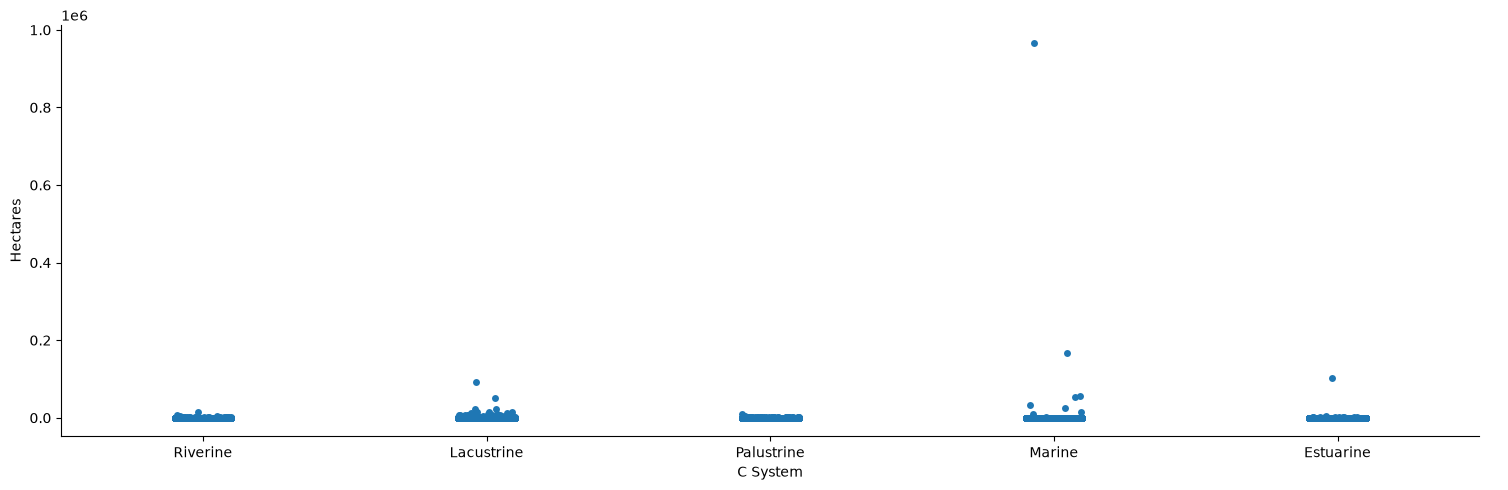

In [33]:
# remove the outlier of Marine system 965105 HA
w = sns.catplot(
    data=wetlands,
    x = "C System",
    y="Hectares",
    #hue= "C Class",
    aspect=3,
)


In [42]:
#wetlands breakdown summary stats
wetlands.groupby(["C System", "C Subsystem",])["Hectares"].describe()

count         mean           std       min  \
C System   C Subsystem                                                       
Estuarine  Intertidal          3679.0    11.689372     54.190513  1.000674   
           Subtidal             197.0   613.427252   7301.873739  1.001185   
Lacustrine Limnetic            2976.0   127.220773   2023.637572  1.001438   
           Littoral            4603.0    87.912316    633.473691  1.001021   
Marine     Intertidal          1042.0    11.188858     26.652599  1.000610   
           Subtidal             279.0  4765.654146  58790.023456  1.001244   
Palustrine N/A                96236.0     7.050050     50.051133  1.000001   
Riverine   Intermittent       55271.0     5.202312     43.576067  1.000027   
           Lower Perennial     3299.0    11.170021     88.856927  1.000225   
           Tidal                237.0    82.414191    924.192438  1.002073   
           Unknown Perennial   4483.0     2.853128      5.167062  1.000175   
           Upper Perennial     6836.0     7.558184     33.012311  1.000129   

                                   25%        50%        75%            max  
C System   C Subsystem                                                       
Estuarine  Intertidal         1.716648   3.087965   7.325557    1860.163426  
           Subtidal           2.331907   5.732612  28.266596  102426.777041  
Lacustrine Limnetic           2.432406   7.172634  17.123940   91269.162135  
           Littoral           3.399686  10.608157  27.589019   22668.463319  
Marine     Intertidal         1.721926   3.454783   9.300195     366.504411  
           Subtidal           2.302901   5.932721  22.018541  965105.257759  
Palustrine N/A                1.422914   2.265997   4.666383    9245.560676  
Riverine   Intermittent       1.300149   1.856070   3.369811    6388.955318  
           Lower Perennial    1.436195   2.304306   5.152307    3988.659332  
           Tidal              1.720135   3.458964  11.024752   14179.963452  
           Unknown Perennial  1.273500   1.725928   2.788290     179.394447  
           Upper Perennial    1.480553   2.459005   5.220324    1532.849085

In [39]:
wetlands.groupby(["C Class"])["Hectares"].describe()

,count,mean,std,min,25%,50%,75%,max
C Class,,,,,,,,
Aquatic Bed,2333.0,12.948859,93.270026,1.001075,1.419052,2.311014,4.947724,3633.778976
Emergent,46815.0,9.480727,43.586574,1.000011,1.523070,2.684393,6.490100,3583.881494
Forested,11856.0,4.058537,9.623360,1.000140,1.374002,2.044203,3.750269,468.817484
Reef,35.0,3.160408,2.305140,1.071266,2.043360,2.657400,3.331701,14.416590
Rock Bottom,978.0,7.776753,26.530279,1.002472,1.541463,2.483428,5.560584,592.464237
Rocky Shore,549.0,6.100416,14.434388,1.000610,1.391839,2.378400,5.713864,267.185804
Scrub-Shrub,25347.0,5.248494,27.263549,1.000004,1.397140,2.143439,4.077576,2781.144998
Streambed,55478.0,5.195657,43.495484,1.000027,1.300412,1.857632,3.372134,6388.955318
Unconsolidated Bottom,22111.0,91.411716,6693.323367,1.000001,1.407567,2.273401,5.131124,965105.257759
